# Cross-Market Technical Trading Strategy Analysis

This notebook studies the relationship between the **US (NASDAQ)** and **Indian (NSE)** equity
markets, and then backtests three classic technical-analysis trading strategies —
**Keltner Channel**, **Bollinger Bands**, and **MACD** — on both markets.

**Structure**
1. Setup & data collection
2. Lead-lag correlation between NASDAQ and NSE
3. Shared helper functions (indicators + performance metrics)
4. Keltner Channel strategy — NSEI & NASDAQ
5. Bollinger Bands strategy — NSEI & NASDAQ
6. MACD strategy — NSEI & NASDAQ
7. Summary comparison of all strategies


## 1. Setup & Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# Start date used for every download in this notebook
START_DATE = '2010-01-01'


### 1.1 Download the two index series

We pull the daily close prices for:
- **NASDAQ Composite** (`^IXIC`)
- **NSE Nifty 50** (`^NSEI`)

and combine them into a single DataFrame for the correlation study below.

In [ ]:
nasdaq_data = yf.download('^IXIC', start=START_DATE)
nse_data = yf.download('^NSEI', start=START_DATE)

nasdaq_close = nasdaq_data['Close']
nse_close = nse_data['Close']

df_indices = pd.concat([nasdaq_close, nse_close], axis=1)
df_indices.columns = ['NASDAQ', 'NSE']
df_indices.head()


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
C:\Users\HP\AppData\Local\Temp\ipykernel_30020\3184636913.py:7: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df_indices = pd.concat([nasdaq_close, nse_close], axis=1)


,NASDAQ,NSE
Date,,
2010-01-04,2308.419922,5232.200195
2010-01-05,2308.709961,5277.899902
2010-01-06,2301.090088,5281.799805
2010-01-07,2300.050049,5263.100098
2010-01-08,2317.169922,5244.750000


## 2. Lead-Lag Correlation Between NASDAQ and NSE

First, a simple same-day correlation of closing prices, followed by a proper
**lead-lag analysis**: does yesterday's NSE *return* say anything about today's
NASDAQ *return*? Because Indian markets close before US markets open, this can
reveal whether NSE moves "lead" NASDAQ moves by one trading day.

In [ ]:
same_day_corr = df_indices['NASDAQ'].corr(df_indices['NSE'])
print('Same-day price correlation:', same_day_corr)


Same-day price correlation: 0.9677439105069516


In [ ]:
# Daily returns for each index
nasdaq_returns = nasdaq_data['Close'].pct_change()
nse_returns = nse_data['Close'].pct_change()

# Shift NSE returns back by one day so that "yesterday's NSE return"
# lines up with "today's NASDAQ return" on the same row
lagged_nse_returns = nse_returns.shift(1)

df_lead_lag = pd.concat([nasdaq_returns, nse_returns, lagged_nse_returns], axis=1)
df_lead_lag.columns = ['NASDAQ_Returns', 'NSE_Returns', 'Lagged_NSE_Returns']

lead_lag_correlation = df_lead_lag['NASDAQ_Returns'].corr(df_lead_lag['Lagged_NSE_Returns'])
print("Correlation between today's NASDAQ return and yesterday's NSE return:", lead_lag_correlation)


Correlation between today's NASDAQ return and yesterday's NSE return: -0.041421401163666646


C:\Users\HP\AppData\Local\Temp\ipykernel_30020\1810188682.py:9: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df_lead_lag = pd.concat([nasdaq_returns, nse_returns, lagged_nse_returns], axis=1)


## 3. Shared Helper Functions

Every strategy below produces a series of **buy prices** and **sell prices**.
To avoid repeating the same clean-up / metric code three times, we define a
small, reusable toolkit once:

- `sma`, `bollinger_bands`, `keltner_channel`, `compute_macd` — indicator builders
- `extract_trades` — turns raw buy/sell price arrays (full of NaNs) into two
  aligned arrays of completed trades
- `trade_returns` — % return per completed trade
- `sharpe_ratio`, `sortino_ratio`, `max_drawdown`, `cumulative_return` — performance metrics
- `performance_summary` — prints + returns all metrics for one strategy in one call


In [ ]:
def sma(data, window):
    """Simple moving average."""
    return data.rolling(window=window).mean()


def bollinger_bands(data, sma_series, window, num_std=2.06):
    """Upper/lower Bollinger Bands around a given moving average."""
    std = data.rolling(window=window).std()
    upper_bb = sma_series + std * num_std
    lower_bb = sma_series - std * num_std
    return upper_bb, lower_bb


def keltner_channel(high, low, close, ema_lookback, multiplier, atr_lookback):
    """Middle/upper/lower Keltner Channel bands based on the Average True Range (ATR)."""
    tr1 = high - low
    tr2 = (high - close.shift()).abs()   # gap-up openings
    tr3 = (low - close.shift()).abs()    # gap-down openings
    true_range = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)

    atr = true_range.ewm(alpha=1 / atr_lookback).mean()
    middle = close.ewm(span=ema_lookback).mean()
    upper = middle + multiplier * atr
    lower = middle - multiplier * atr
    return middle, upper, lower


def compute_macd(df, n_fast, n_slow, n_smooth):
    """Adds MACD, MACD signal line, and MACD histogram columns to df (based on Close)."""
    close = df['Close'].squeeze()
    fast_ema = close.ewm(span=n_fast, min_periods=n_fast).mean()
    slow_ema = close.ewm(span=n_slow, min_periods=n_slow).mean()

    df = df.copy()
    df['MACD'] = fast_ema - slow_ema
    df['MACDsig'] = df['MACD'].ewm(span=n_smooth, min_periods=n_smooth).mean()
    df['MACDhist'] = df['MACD'] - df['MACDsig']
    return df


In [ ]:
def extract_trades(buy_prices, sell_prices):
    """Drop NaNs from raw buy/sell signal arrays and align them into pairs of
    completed trades (buy[i] paired with sell[i])."""
    buy_arr = np.asarray(buy_prices, dtype=float)
    sell_arr = np.asarray(sell_prices, dtype=float)

    buy_arr = buy_arr[~np.isnan(buy_arr)]
    sell_arr = sell_arr[~np.isnan(sell_arr)]

    n = min(len(buy_arr), len(sell_arr))
    return buy_arr[:n], sell_arr[:n]


def trade_returns(buy_arr, sell_arr):
    """Percentage return for each completed (buy -> sell) trade."""
    return (sell_arr - buy_arr) / buy_arr


def sharpe_ratio(returns, risk_free_rate=0.0):
    mean_return = returns.mean()
    sigma = returns.std()
    return (mean_return - risk_free_rate) / sigma


def sortino_ratio(returns, risk_free_rate=0.0):
    mean_return = returns.mean()
    downside_std = returns[returns < 0].std()
    return (mean_return - risk_free_rate) / downside_std


def max_drawdown(returns):
    """Max drawdown of the equity curve built by compounding trade returns."""
    equity = 100 * np.cumprod(1 + returns)
    running_max = np.maximum.accumulate(equity)
    drawdown = (equity - running_max) / running_max
    return drawdown.min()


def cumulative_return(returns):
    return np.prod(1 + returns) - 1


def performance_summary(name, buy_prices, sell_prices, risk_free_rate=0.0):
    """Extracts trades and prints/returns the full performance metric set for one strategy.

    If the strategy produced no completed trades, metrics are reported as NaN
    instead of raising an error.
    """
    buy_arr, sell_arr = extract_trades(buy_prices, sell_prices)

    if len(buy_arr) == 0:
        print(f'--- {name} ---')
        print('No completed trades were generated by this strategy on this data.')
        summary = {
            'Strategy': name, 'Trades': 0, 'Avg Return %': np.nan, 'Std Dev %': np.nan,
            'Best Trade %': np.nan, 'Worst Trade %': np.nan, 'Cumulative Return %': np.nan,
            'Sharpe Ratio': np.nan, 'Sortino Ratio': np.nan, 'Max Drawdown %': np.nan,
        }
        return summary

    returns = trade_returns(buy_arr, sell_arr)

    summary = {
        'Strategy': name,
        'Trades': len(returns),
        'Avg Return %': returns.mean() * 100,
        'Std Dev %': returns.std() * 100,
        'Best Trade %': returns.max() * 100,
        'Worst Trade %': returns.min() * 100,
        'Cumulative Return %': cumulative_return(returns) * 100,
        'Sharpe Ratio': sharpe_ratio(returns, risk_free_rate),
        'Sortino Ratio': sortino_ratio(returns, risk_free_rate),
        'Max Drawdown %': max_drawdown(returns) * 100,
    }

    print(f'--- {name} ---')
    for k, v in summary.items():
        if k not in ('Strategy', 'Trades'):
            print(f'{k}: {v:.4f}')
        else:
            print(f'{k}: {v}')
    return summary


# Collect one summary dict per strategy here; used to build the comparison
# table in the final section of the notebook.
all_results = []


## 4. Keltner Channel Strategy

**Idea:** when price closes below the lower band and the very next bar turns
back up, treat that as a *buy* signal; when price closes above the upper band
and the next bar turns back down, treat that as a *sell* signal.

In [ ]:
def implement_kc_strategy(prices, kc_upper, kc_lower):
    prices = prices.to_numpy()
    kc_upper = kc_upper.to_numpy()
    kc_lower = kc_lower.to_numpy()

    buy_price, sell_price, signal_list = [], [], []
    signal = 0

    for i in range(len(prices) - 1):
        if prices[i] < kc_lower[i] and prices[i + 1] > prices[i]:
            if signal != 1:
                buy_price.append(prices[i]); sell_price.append(np.nan)
                signal = 1
            else:
                buy_price.append(np.nan); sell_price.append(np.nan)
        elif prices[i] > kc_upper[i] and prices[i + 1] < prices[i]:
            if signal != -1:
                buy_price.append(np.nan); sell_price.append(prices[i])
                signal = -1
            else:
                buy_price.append(np.nan); sell_price.append(np.nan)
        else:
            buy_price.append(np.nan); sell_price.append(np.nan)
        signal_list.append(signal)

    return buy_price, sell_price, signal_list


### 4.1 NSEI — Keltner Channel

In [ ]:
df_nsei = yf.download('^NSEI', start=START_DATE)
df_nsei.columns = [c[0] if isinstance(c, tuple) else c for c in df_nsei.columns]

df_nsei['kc_middle'], df_nsei['kc_upper'], df_nsei['kc_lower'] = keltner_channel(
    df_nsei['High'], df_nsei['Low'], df_nsei['Close'],
    ema_lookback=6, multiplier=2, atr_lookback=10,
)
df_nsei.head()


[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume,kc_middle,kc_upper,kc_lower
Date,,,,,,,,
2010-01-04,5232.200195,5238.450195,5167.100098,5200.899902,0,5232.200195,5374.900391,5089.500000
2010-01-05,5277.899902,5288.350098,5242.399902,5277.149902,0,5258.858358,5385.558347,5132.158368
2010-01-06,5281.799805,5310.850098,5260.049805,5278.149902,0,5269.171485,5386.609702,5151.733268
2010-01-07,5263.100098,5302.549805,5244.750000,5281.799805,0,5266.826343,5383.729926,5149.922761
2010-01-08,5244.750000,5276.750000,5234.700195,5264.250000,0,5259.078163,5367.971203,5150.185123


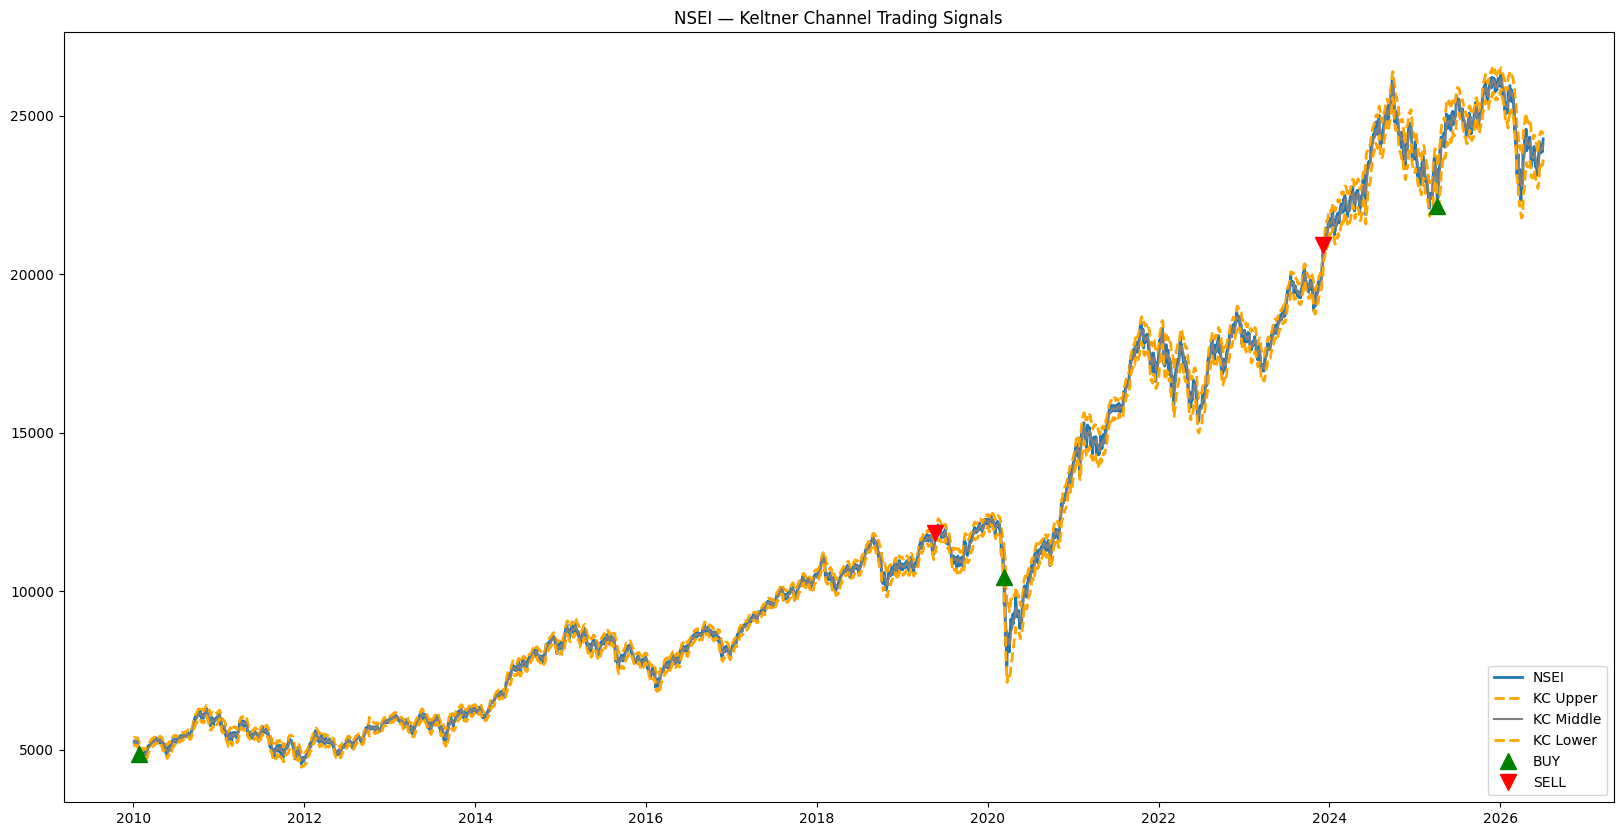

In [ ]:
kc_buy_nsei, kc_sell_nsei, kc_signal_nsei = implement_kc_strategy(
    df_nsei['Close'], df_nsei['kc_upper'], df_nsei['kc_lower']
)
df_nsei_kc = df_nsei.iloc[:-1].copy()

plt.figure(figsize=(20, 10))
plt.plot(df_nsei_kc['Close'], linewidth=2, label='NSEI')
plt.plot(df_nsei_kc['kc_upper'], linewidth=2, color='orange', linestyle='--', label='KC Upper')
plt.plot(df_nsei_kc['kc_middle'], linewidth=1.5, color='grey', label='KC Middle')
plt.plot(df_nsei_kc['kc_lower'], linewidth=2, color='orange', linestyle='--', label='KC Lower')
plt.plot(df_nsei_kc.index, kc_buy_nsei, marker='^', color='green', markersize=12, linewidth=0, label='BUY')
plt.plot(df_nsei_kc.index, kc_sell_nsei, marker='v', color='red', markersize=12, linewidth=0, label='SELL')
plt.legend(loc='lower right')
plt.title('NSEI — Keltner Channel Trading Signals')
plt.show()


In [ ]:
result = performance_summary('Keltner Channel - NSEI', kc_buy_nsei, kc_sell_nsei)
all_results.append(result)


--- Keltner Channel - NSEI ---
Strategy: Keltner Channel - NSEI
Trades: 2
Avg Return %: 122.0293
Std Dev %: 21.6963
Best Trade %: 143.7257
Worst Trade %: 100.3330
Cumulative Return %: 388.2628
Sharpe Ratio: 5.6244
Sortino Ratio: nan
Max Drawdown %: 0.0000


d:\Python Projects\venvs\ml_env\Lib\site-packages\numpy\_core\_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
d:\Python Projects\venvs\ml_env\Lib\site-packages\numpy\_core\_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
d:\Python Projects\venvs\ml_env\Lib\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


### 4.2 NASDAQ (NDX) — Keltner Channel

In [ ]:
df_ndx = yf.download('^NDX', start=START_DATE)
df_ndx.columns = [c[0] if isinstance(c, tuple) else c for c in df_ndx.columns]

df_ndx['kc_middle'], df_ndx['kc_upper'], df_ndx['kc_lower'] = keltner_channel(
    df_ndx['High'], df_ndx['Low'], df_ndx['Close'],
    ema_lookback=6, multiplier=2, atr_lookback=10,
)
df_ndx.head()


[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume,kc_middle,kc_upper,kc_lower
Date,,,,,,,,
2010-01-04,1886.699951,1890.020020,1881.630005,1882.689941,1931380000,1886.699951,1903.479980,1869.919922
2010-01-05,1888.430054,1891.329956,1877.520020,1887.280029,2367860000,1887.709178,1910.194388,1865.223967
2010-01-06,1878.420044,1893.209961,1873.900024,1887.910034,2253340000,1883.533329,1911.972289,1855.094368
2010-01-07,1876.719971,1881.329956,1867.619995,1878.160034,2270050000,1880.901592,1909.044234,1852.758950
2010-01-08,1892.589966,1893.250000,1868.550049,1870.900024,2145390000,1885.003885,1918.337429,1851.670342


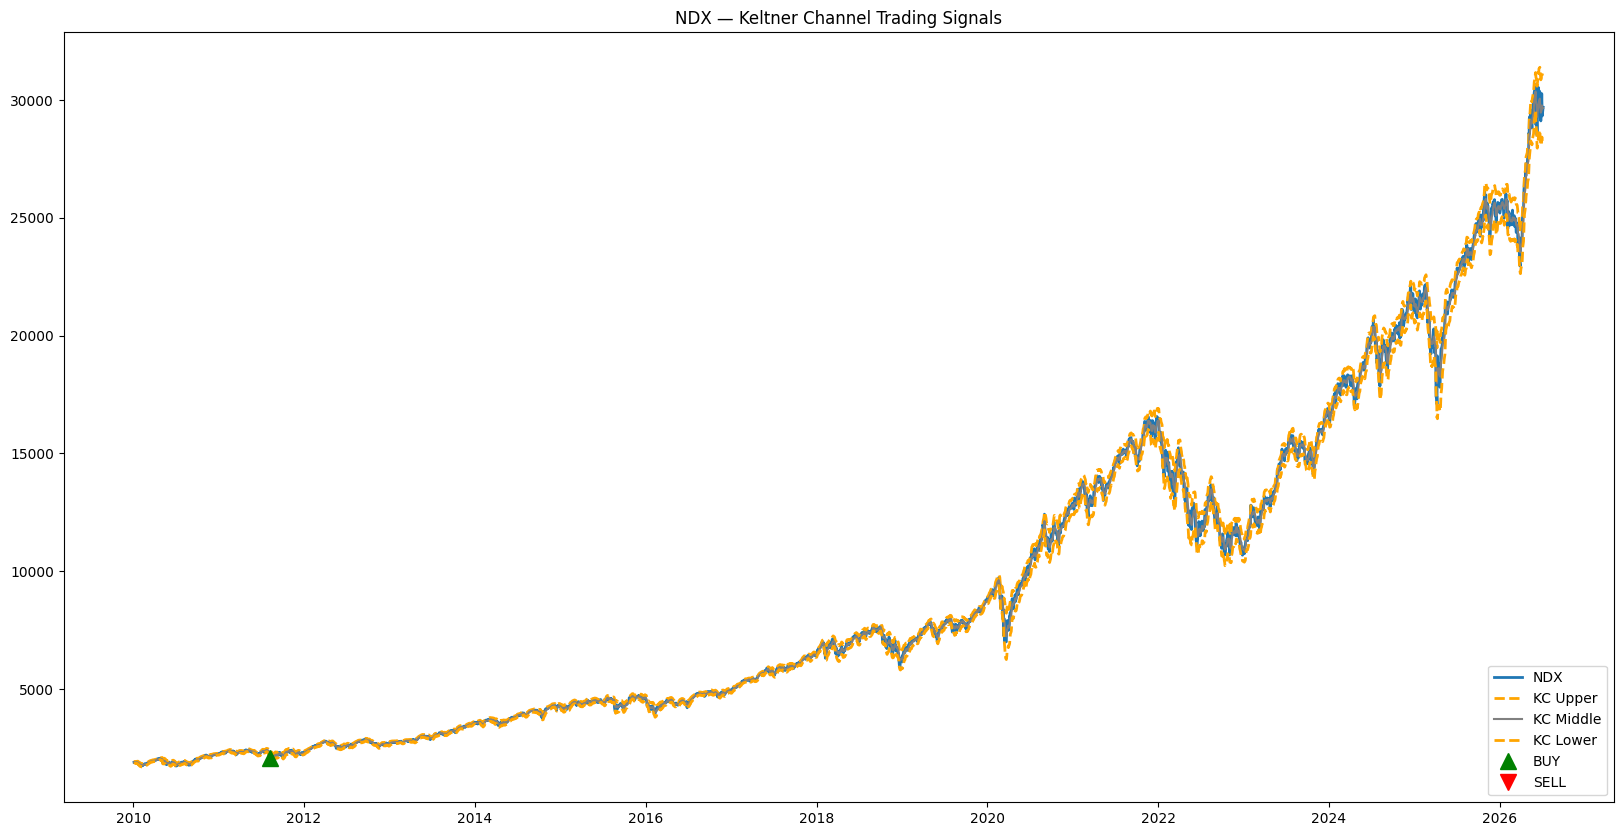

In [ ]:
kc_buy_ndx, kc_sell_ndx, kc_signal_ndx = implement_kc_strategy(
    df_ndx['Close'], df_ndx['kc_upper'], df_ndx['kc_lower']
)
df_ndx_kc = df_ndx.iloc[:-1].copy()

plt.figure(figsize=(20, 10))
plt.plot(df_ndx_kc['Close'], linewidth=2, label='NDX')
plt.plot(df_ndx_kc['kc_upper'], linewidth=2, color='orange', linestyle='--', label='KC Upper')
plt.plot(df_ndx_kc['kc_middle'], linewidth=1.5, color='grey', label='KC Middle')
plt.plot(df_ndx_kc['kc_lower'], linewidth=2, color='orange', linestyle='--', label='KC Lower')
plt.plot(df_ndx_kc.index, kc_buy_ndx, marker='^', color='green', markersize=12, linewidth=0, label='BUY')
plt.plot(df_ndx_kc.index, kc_sell_ndx, marker='v', color='red', markersize=12, linewidth=0, label='SELL')
plt.legend(loc='lower right')
plt.title('NDX — Keltner Channel Trading Signals')
plt.show()


In [ ]:
result = performance_summary('Keltner Channel - NDX', kc_buy_ndx, kc_sell_ndx)
all_results.append(result)


--- Keltner Channel - NDX ---
No completed trades were generated by this strategy on this data.


## 5. Bollinger Bands Strategy

**Idea:** a *buy* signal fires when price crosses back **up** through the
lower band (was below, now above); a *sell* signal fires when price crosses
back **down** through the upper band (was above, now below).

In [ ]:
def implement_bb_strategy(data, lower_bb, upper_bb):
    buy_price, sell_price, signal_list = [], [], []
    signal = 0

    for i in range(1, len(data)):
        if data.iloc[i - 1] < lower_bb.iloc[i - 1] and data.iloc[i] > lower_bb.iloc[i]:
            if signal != 1:
                buy_price.append(data.iloc[i]); sell_price.append(np.nan)
                signal = 1
            else:
                buy_price.append(np.nan); sell_price.append(np.nan)
        elif data.iloc[i - 1] > upper_bb.iloc[i - 1] and data.iloc[i] < upper_bb.iloc[i]:
            if signal != -1:
                buy_price.append(np.nan); sell_price.append(data.iloc[i])
                signal = -1
            else:
                buy_price.append(np.nan); sell_price.append(np.nan)
        else:
            buy_price.append(np.nan); sell_price.append(np.nan)
        signal_list.append(signal)

    # Pad the first row (no i-1 to compare against) with no-signal
    return [np.nan] + buy_price, [np.nan] + sell_price, [0] + signal_list


### 5.1 NSEI — Bollinger Bands

In [ ]:
df_nsei_bb = yf.download('^NSEI', start=START_DATE)
df_nsei_bb.columns = [c[0] if isinstance(c, tuple) else c for c in df_nsei_bb.columns]
close_nsei_bb = df_nsei_bb['Close'].squeeze()

df_nsei_bb['SMA'] = sma(close_nsei_bb, window=5)
df_nsei_bb['upper_bb'], df_nsei_bb['lower_bb'] = bollinger_bands(close_nsei_bb, df_nsei_bb['SMA'], window=10)
df_nsei_bb.head()


[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume,SMA,upper_bb,lower_bb
Date,,,,,,,,
2010-01-04,5232.200195,5238.450195,5167.100098,5200.899902,0,NaN,NaN,NaN
2010-01-05,5277.899902,5288.350098,5242.399902,5277.149902,0,NaN,NaN,NaN
2010-01-06,5281.799805,5310.850098,5260.049805,5278.149902,0,NaN,NaN,NaN
2010-01-07,5263.100098,5302.549805,5244.750000,5281.799805,0,NaN,NaN,NaN
2010-01-08,5244.750000,5276.750000,5234.700195,5264.250000,0,5259.95,NaN,NaN


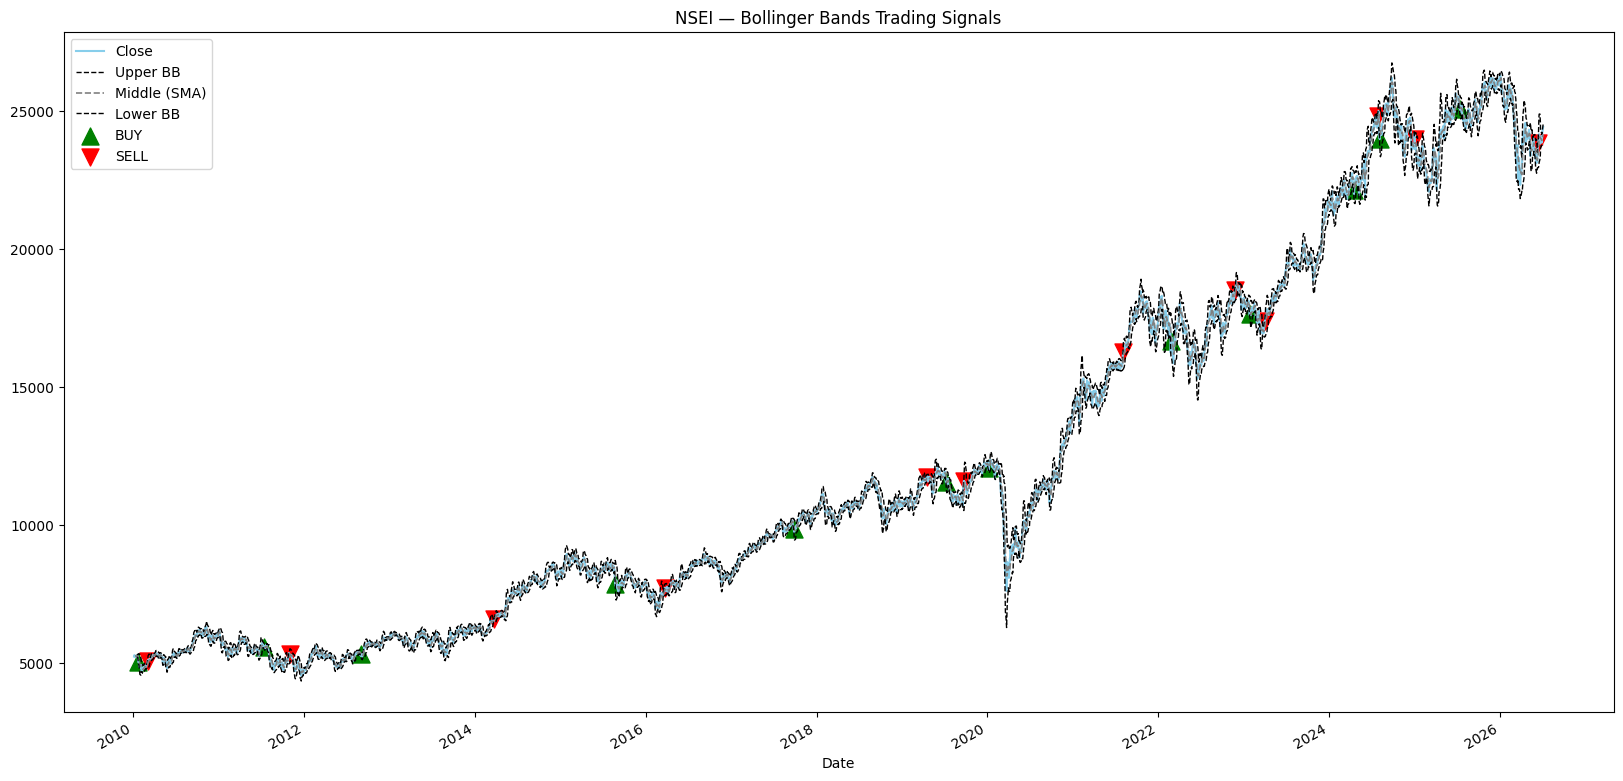

In [ ]:
buy_nsei_bb, sell_nsei_bb, signal_nsei_bb = implement_bb_strategy(
    close_nsei_bb, df_nsei_bb['lower_bb'], df_nsei_bb['upper_bb']
)

plt.figure(figsize=(20, 10))
df_nsei_bb['Close'].plot(label='Close', color='skyblue')
df_nsei_bb['upper_bb'].plot(label='Upper BB', linestyle='--', linewidth=1, color='black')
df_nsei_bb['SMA'].plot(label='Middle (SMA)', linestyle='--', linewidth=1.2, color='grey')
df_nsei_bb['lower_bb'].plot(label='Lower BB', linestyle='--', linewidth=1, color='black')
plt.scatter(df_nsei_bb.index, buy_nsei_bb, marker='^', color='green', label='BUY', s=150)
plt.scatter(df_nsei_bb.index, sell_nsei_bb, marker='v', color='red', label='SELL', s=150)
plt.legend(loc='upper left')
plt.title('NSEI — Bollinger Bands Trading Signals')
plt.show()


In [ ]:
result = performance_summary('Bollinger Bands - NSEI', buy_nsei_bb, sell_nsei_bb, risk_free_rate=0.03)
all_results.append(result)


--- Bollinger Bands - NSEI ---
Strategy: Bollinger Bands - NSEI
Trades: 12
Avg Return %: 7.4582
Std Dev %: 12.2892
Best Trade %: 34.8948
Worst Trade %: -4.8975
Cumulative Return %: 120.1350
Sharpe Ratio: 0.3628
Sortino Ratio: 2.9260
Max Drawdown %: -4.8975


### 5.2 NASDAQ (NDAQ) — Bollinger Bands

In [ ]:
df_ndaq_bb = yf.download('NDAQ', start=START_DATE)
df_ndaq_bb.columns = [c[0] if isinstance(c, tuple) else c for c in df_ndaq_bb.columns]
close_ndaq_bb = df_ndaq_bb['Close'].squeeze()

df_ndaq_bb['SMA'] = sma(close_ndaq_bb, window=5)
df_ndaq_bb['upper_bb'], df_ndaq_bb['lower_bb'] = bollinger_bands(close_ndaq_bb, df_ndaq_bb['SMA'], window=10)
df_ndaq_bb.head()


[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume,SMA,upper_bb,lower_bb
Date,,,,,,,,
2010-01-04,5.384234,5.434777,5.293787,5.299107,6514500,NaN,NaN,NaN
2010-01-05,5.400195,5.405515,5.301767,5.301767,4445100,NaN,NaN,NaN
2010-01-06,5.397536,5.416158,5.362954,5.373595,7340100,NaN,NaN,NaN
2010-01-07,5.325711,5.400197,5.291128,5.386895,8498400,NaN,NaN,NaN
2010-01-08,5.381575,5.400197,5.288469,5.328372,4347600,5.37785,NaN,NaN


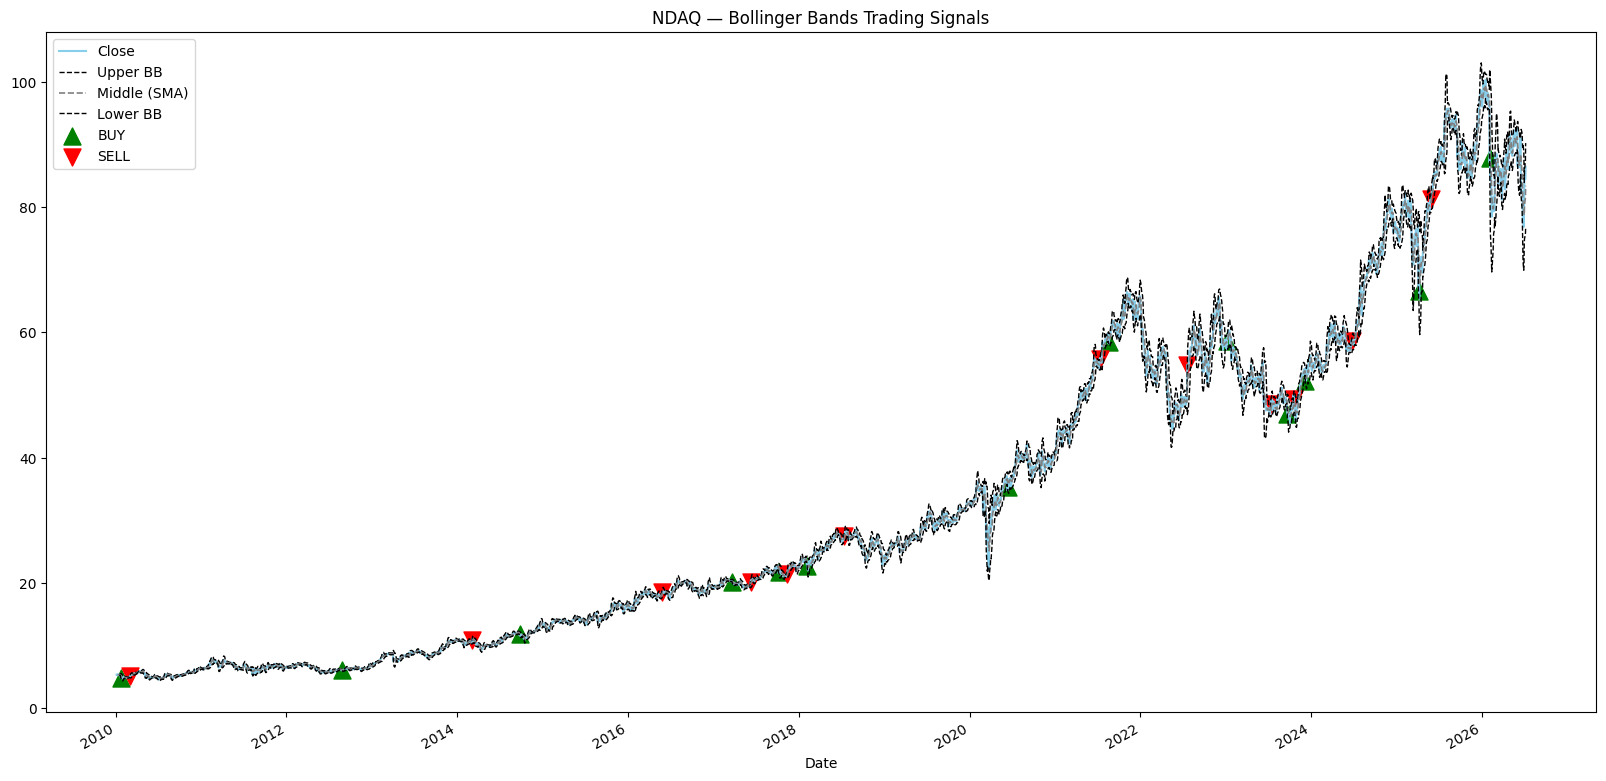

In [ ]:
buy_ndaq_bb, sell_ndaq_bb, signal_ndaq_bb = implement_bb_strategy(
    close_ndaq_bb, df_ndaq_bb['lower_bb'], df_ndaq_bb['upper_bb']
)

plt.figure(figsize=(20, 10))
df_ndaq_bb['Close'].plot(label='Close', color='skyblue')
df_ndaq_bb['upper_bb'].plot(label='Upper BB', linestyle='--', linewidth=1, color='black')
df_ndaq_bb['SMA'].plot(label='Middle (SMA)', linestyle='--', linewidth=1.2, color='grey')
df_ndaq_bb['lower_bb'].plot(label='Lower BB', linestyle='--', linewidth=1, color='black')
plt.scatter(df_ndaq_bb.index, buy_ndaq_bb, marker='^', color='green', label='BUY', s=150)
plt.scatter(df_ndaq_bb.index, sell_ndaq_bb, marker='v', color='red', label='SELL', s=150)
plt.legend(loc='upper left')
plt.title('NDAQ — Bollinger Bands Trading Signals')
plt.show()


In [ ]:
result = performance_summary('Bollinger Bands - NDAQ', buy_ndaq_bb, sell_ndaq_bb, risk_free_rate=0.03)
all_results.append(result)


--- Bollinger Bands - NDAQ ---
Strategy: Bollinger Bands - NDAQ
Trades: 12
Avg Return %: 19.7942
Std Dev %: 28.6201
Best Trade %: 80.6007
Worst Trade %: -17.2341
Cumulative Return %: 536.7764
Sharpe Ratio: 0.5868
Sortino Ratio: 2.5167
Max Drawdown %: -22.4380


## 6. MACD Strategy

**Idea:** a *buy* signal fires the first time the MACD line crosses **above**
its signal line; a *sell* signal fires the first time it crosses **below**.
The `flag` variable prevents repeated buy/sell signals while the MACD stays
on the same side of the signal line.

In [ ]:
def generate_macd_signals(df):
    close = df['Close'].to_numpy()
    macd = df['MACD'].to_numpy()
    macd_sig = df['MACDsig'].to_numpy()

    buy_list, sell_list = [], []
    flag = -1  # -1 = no position yet, 1 = long, 0 = short/flat

    for i in range(len(df)):
        if np.isnan(macd[i]) or np.isnan(macd_sig[i]):
            buy_list.append(np.nan); sell_list.append(np.nan)
            continue

        if macd[i] > macd_sig[i]:
            sell_list.append(np.nan)
            if flag != 1:
                buy_list.append(close[i]); flag = 1
            else:
                buy_list.append(np.nan)
        elif macd[i] < macd_sig[i]:
            buy_list.append(np.nan)
            if flag != 0:
                sell_list.append(close[i]); flag = 0
            else:
                sell_list.append(np.nan)
        else:
            buy_list.append(np.nan); sell_list.append(np.nan)

    return buy_list, sell_list


### 6.1 NSEI — MACD

In [ ]:
df_nsei_macd = yf.download('^NSEI', start=START_DATE)
df_nsei_macd.columns = [c[0] if isinstance(c, tuple) else c for c in df_nsei_macd.columns]

df_nsei_macd = compute_macd(df_nsei_macd, n_fast=52, n_slow=112, n_smooth=52)
df_nsei_macd['buy_sig'], df_nsei_macd['sell_sig'] = generate_macd_signals(df_nsei_macd)
df_nsei_macd.head()


[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume,MACD,MACDsig,MACDhist,buy_sig,sell_sig
Date,,,,,,,,,,
2010-01-04,5232.200195,5238.450195,5167.100098,5200.899902,0,NaN,NaN,NaN,NaN,NaN
2010-01-05,5277.899902,5288.350098,5242.399902,5277.149902,0,NaN,NaN,NaN,NaN,NaN
2010-01-06,5281.799805,5310.850098,5260.049805,5278.149902,0,NaN,NaN,NaN,NaN,NaN
2010-01-07,5263.100098,5302.549805,5244.750000,5281.799805,0,NaN,NaN,NaN,NaN,NaN
2010-01-08,5244.750000,5276.750000,5234.700195,5264.250000,0,NaN,NaN,NaN,NaN,NaN


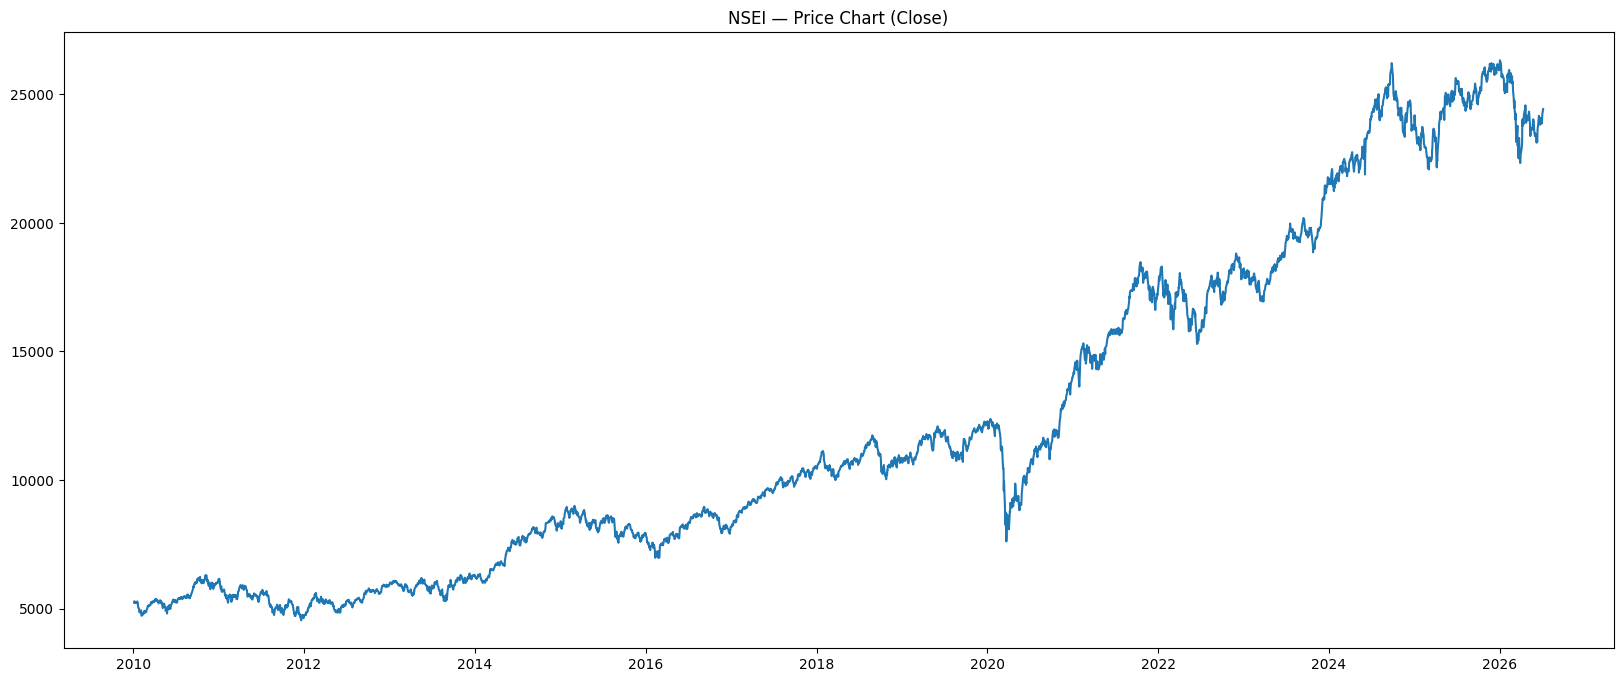

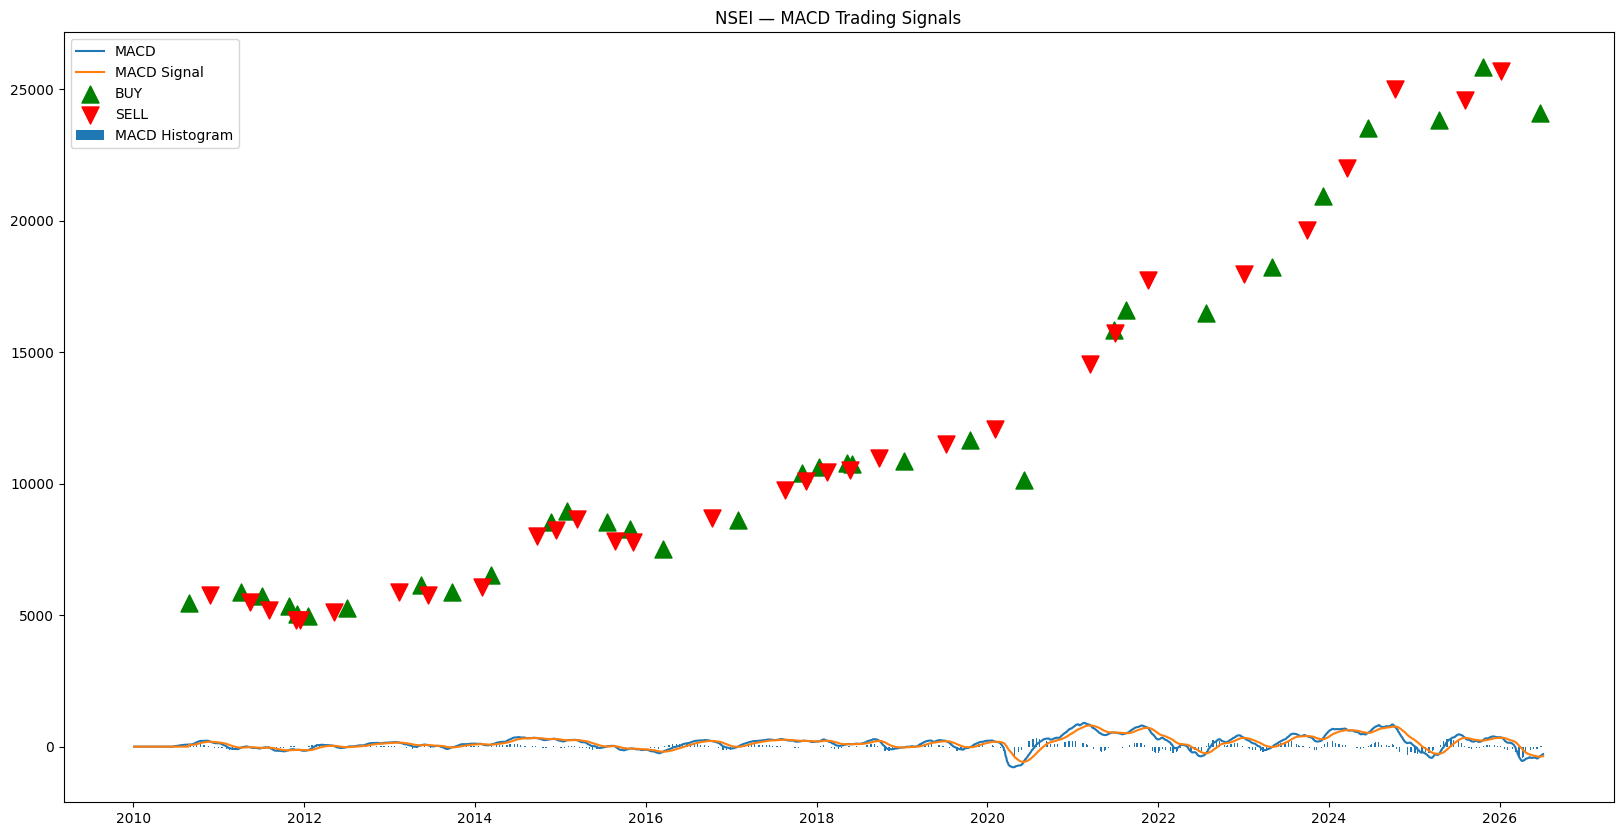

In [ ]:
plt.figure(figsize=(20, 8))
plt.plot(df_nsei_macd['Close'])
plt.title('NSEI — Price Chart (Close)')
plt.show()

plt.figure(figsize=(20, 10))
plt.plot(df_nsei_macd['MACD'].fillna(0), label='MACD')
plt.plot(df_nsei_macd['MACDsig'].fillna(0), label='MACD Signal')
plt.bar(df_nsei_macd.index, df_nsei_macd['MACDhist'].fillna(0), width=0.5, label='MACD Histogram')
plt.scatter(df_nsei_macd.index, df_nsei_macd['buy_sig'], marker='^', color='green', label='BUY', s=150)
plt.scatter(df_nsei_macd.index, df_nsei_macd['sell_sig'], marker='v', color='red', label='SELL', s=150)
plt.legend()
plt.title('NSEI — MACD Trading Signals')
plt.show()


In [ ]:
result = performance_summary('MACD - NSEI', df_nsei_macd['buy_sig'], df_nsei_macd['sell_sig'])
all_results.append(result)


--- MACD - NSEI ---
Strategy: MACD - NSEI
Trades: 31
Avg Return %: 3.2620
Std Dev %: 10.5543
Best Trade %: 43.5381
Worst Trade %: -10.3643
Cumulative Return %: 133.5440
Sharpe Ratio: 0.3091
Sortino Ratio: 1.0973
Max Drawdown %: -27.5857


### 6.2 NASDAQ (NDAQ) — MACD

In [ ]:
df_ndaq_macd = yf.download('NDAQ', start=START_DATE)
df_ndaq_macd.columns = [c[0] if isinstance(c, tuple) else c for c in df_ndaq_macd.columns]

df_ndaq_macd = compute_macd(df_ndaq_macd, n_fast=52, n_slow=112, n_smooth=52)
df_ndaq_macd['buy_sig'], df_ndaq_macd['sell_sig'] = generate_macd_signals(df_ndaq_macd)
df_ndaq_macd.head()


[*********************100%***********************]  1 of 1 completed


,Close,High,Low,Open,Volume,MACD,MACDsig,MACDhist,buy_sig,sell_sig
Date,,,,,,,,,,
2010-01-04,5.384236,5.434779,5.293789,5.299109,6514500,NaN,NaN,NaN,NaN,NaN
2010-01-05,5.400196,5.405516,5.301768,5.301768,4445100,NaN,NaN,NaN,NaN,NaN
2010-01-06,5.397535,5.416157,5.362953,5.373593,7340100,NaN,NaN,NaN,NaN,NaN
2010-01-07,5.325710,5.400196,5.291128,5.386894,8498400,NaN,NaN,NaN,NaN,NaN
2010-01-08,5.381573,5.400195,5.288467,5.328370,4347600,NaN,NaN,NaN,NaN,NaN


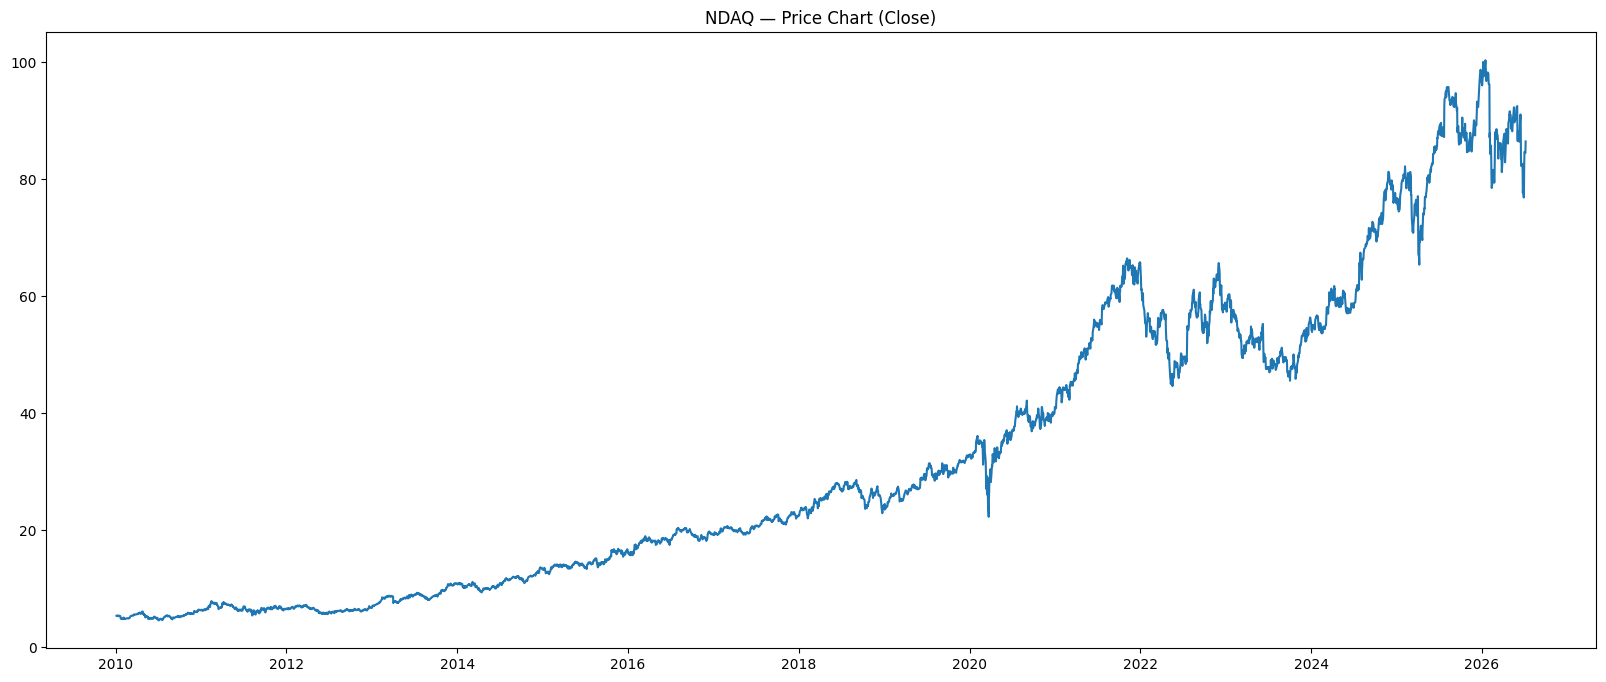

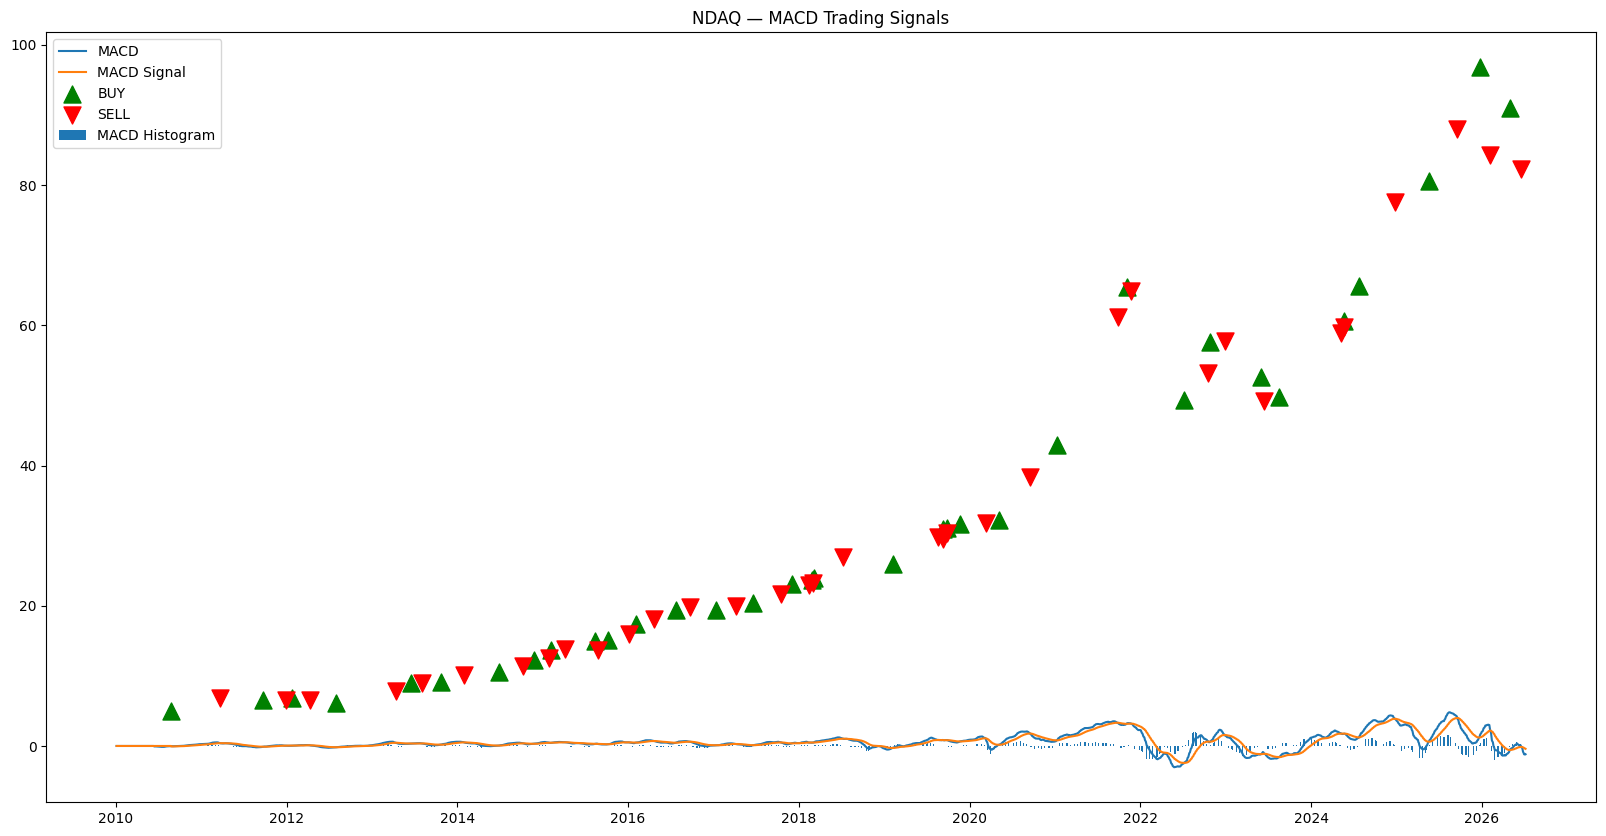

In [ ]:
plt.figure(figsize=(20, 8))
plt.plot(df_ndaq_macd['Close'])
plt.title('NDAQ — Price Chart (Close)')
plt.show()

plt.figure(figsize=(20, 10))
plt.plot(df_ndaq_macd['MACD'].fillna(0), label='MACD')
plt.plot(df_ndaq_macd['MACDsig'].fillna(0), label='MACD Signal')
plt.bar(df_ndaq_macd.index, df_ndaq_macd['MACDhist'].fillna(0), width=0.5, label='MACD Histogram')
plt.scatter(df_ndaq_macd.index, df_ndaq_macd['buy_sig'], marker='^', color='green', label='BUY', s=150)
plt.scatter(df_ndaq_macd.index, df_ndaq_macd['sell_sig'], marker='v', color='red', label='SELL', s=150)
plt.legend()
plt.title('NDAQ — MACD Trading Signals')
plt.show()


In [ ]:
result = performance_summary('MACD - NDAQ', df_ndaq_macd['buy_sig'], df_ndaq_macd['sell_sig'])
all_results.append(result)


--- MACD - NDAQ ---
Strategy: MACD - NDAQ
Trades: 34
Avg Return %: 5.8995
Std Dev %: 12.3347
Best Trade %: 42.3622
Worst Trade %: -12.9592
Cumulative Return %: 466.7821
Sharpe Ratio: 0.4783
Sortino Ratio: 1.4868
Max Drawdown %: -21.3325


## 7. Summary: Comparing All Strategies

A single table pulling together the performance metrics computed above for
every strategy/market combination, so results can be compared at a glance.

In [ ]:
summary_df = pd.DataFrame(all_results).set_index('Strategy')
summary_df


,Trades,Avg Return %,Std Dev %,Best Trade %,Worst Trade %,Cumulative Return %,Sharpe Ratio,Sortino Ratio,Max Drawdown %
Strategy,,,,,,,,,
Keltner Channel - NSEI,2,122.029306,21.696349,143.725655,100.332957,388.262811,5.624417,NaN,0.000000
Keltner Channel - NDX,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Bollinger Bands - NSEI,12,7.458245,12.289248,34.894773,-4.897479,120.134984,0.362776,2.925964,-4.897479
Bollinger Bands - NDAQ,12,19.794184,28.620082,80.600669,-17.234112,536.776368,0.586797,2.516717,-22.437994
MACD - NSEI,31,3.262036,10.554312,43.538096,-10.364320,133.544040,0.309071,1.097306,-27.585652
MACD - NDAQ,34,5.899543,12.334693,42.362209,-12.959164,466.782093,0.478289,1.486804,-21.332535
